# E4 — Esercitazione: pulire un dataset nuovo

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrealorenzon/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb)

## Come funziona un'esercitazione

Rispetto alle lezioni, qui hai **meno indicazioni**: per ogni passo trovi l'obiettivo e un **controllo** per verificare di esserci arrivato. Cosa cercare, sta a te (Google, Gemini, le dispense, i notebook delle lezioni).

- 👥 Si lavora in **gruppi da 3**, con tre ruoli che **ruotano a ogni incontro**: chi **scrive** (condivide lo schermo e scrive il codice nel suo notebook), chi **cerca** (Google, Gemini, dispense), chi **controlla** (il risultato ha senso? il numero torna?). Il codice sta tutto nel notebook di chi scrive, sul **suo fork** (Parte 0): a fine lezione gli altri due ne salvano una copia nel proprio fork (vedi **Consegna**).
- Se il controllo non torna, **non andare avanti**: un errore all'inizio si porta dietro tutto il resto.
- 🆘 Bloccato **fuori dalla lezione**? In Colab: **Condividi** → aggiungi `andrelorenzon+sima2026@gmail.com` come **Editor**, poi scrivigli quale passo non torna.
- Oggi si salva su **GitHub**, non su Drive: **File → Salva una copia in GitHub** (Parte 0).

## Contesto

Un'azienda alimentare ti manda le sue esportazioni mensili del 2022 e del 2023, per paese e prodotto: `esportazioni.xlsx`. Vogliono sapere quanto hanno esportato in ogni paese. Prima, però, i dati vanno puliti: è il lavoro della L3, su un file che non hai mai visto.

Leggi la descrizione delle colonne in [`dati/README.md`](https://github.com/andrealorenzon/SIMA2026/blob/main/dati/README.md): ti servirà.

⏱️ **Prima di iniziare:** se non hai finito il task della L3, completalo ora (circa 20 minuti). Questa esercitazione usa le stesse tecniche su un file nuovo.

## Parte 0 — Lavorare sul proprio fork (15 minuti)

Oggi non lavori sulla copia del docente, ma su **una tua copia della repository** su GitHub: un **fork**. Ogni volta che salvi, Colab registra una versione del notebook (un **commit**) e la manda al tuo fork (un **push**). Alla fine mandi al docente il link alla tua versione.

**Tutti e tre** fanno i passi 0.1 e 0.2. Dal passo 0.3 lavora solo chi scrive.

#### 0.1 L'account GitHub

Se non ce l'hai, crealo su [github.com/signup](https://github.com/signup): serve confermare l'indirizzo email.

#### 0.2 Il fork

1. Da loggato, apri [github.com/andrealorenzon/SIMA2026](https://github.com/andrealorenzon/SIMA2026).
2. In alto a destra: **Fork** → lascia tutto com'è → **Create fork**.

✅ *Controllo:* sei su `github.com/<tuo-utente>/SIMA2026`, e sotto il nome c'è scritto *forked from andrealorenzon/SIMA2026*.

#### 0.3 Apri il notebook dal tuo fork

Il pulsante *Apri in Colab* in cima a questo notebook apre la copia **del docente**: non usarlo. In Colab, invece:

1. **File → Apri notebook** → scheda **GitHub**.
2. Scrivi il tuo nome utente GitHub, scegli la repository `<tuo-utente>/SIMA2026` e il branch `main`.
3. Clicca su `esercitazioni/E04_pulizia/E04_task.ipynb`.

Oppure apri direttamente `https://colab.research.google.com/github/<tuo-utente>/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb`.

✅ *Controllo:* nella barra degli indirizzi c'è il tuo nome utente, non `andrealorenzon`.

#### 0.4 Il primo commit e push

Scrivi i nomi del gruppo nella cella qui sotto, poi:

1. **File → Salva una copia in GitHub**. La prima volta Colab chiede di collegarsi al tuo account GitHub: autorizza.
2. Repository: `<tuo-utente>/SIMA2026`; branch: `main`; percorso: lascia `esercitazioni/E04_pulizia/E04_task.ipynb`.
3. Messaggio di commit: una frase che dice cosa hai fatto, per esempio `E4: nomi del gruppo`.
4. **OK**.

✅ *Controllo:* sul tuo fork, in GitHub, apri il file: in alto c'è il tuo messaggio di commit, di pochi secondi fa.

**Da qui in poi** salva così alla fine di ogni parte, con un messaggio che dice cosa hai fatto (`E4: parte 1, pulizia`). `Ctrl+S` non salva sul tuo fork.

\\**Gruppo** (chi scrive, chi cerca, chi controlla): ...Simone (scrive), Mattia (controlla) , Maria Cristina (cerca)

## Preparazione

Esegui questa cella così com'è: carica le librerie e il file delle esportazioni nella tabella `ex`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ex = pd.read_excel("https://raw.githubusercontent.com/andrealorenzon/SIMA2026/main/dati/esportazioni.xlsx")

In [ ]:
df = ex
display(df.head())

## Parte 1 — Pulizia

### 1. Conosci il file

Guarda le prime righe, le dimensioni e i tipi delle colonne. Scrivi qui sotto **tutti** i problemi che vedi, prima di correggere qualunque cosa.

Problemi:
1) Il valore e' una stringa (e non un float)
2) Il valore ha come separtore decimale una virgola e non il punto (il db e' stato scritto da un italiano)
3) La colonna paese presenta valori non uniformi (es. Gerimania = Germany e DE)

In [20]:
1# scrivi qui il tuo codice
#import pandas as pd
display(ex.shape)
display(ex.head())
ex.info()

(425, 5)

,mese,paese,prodotto,quantita,valore
0,set 2022,Germany,Parmigiano 1kg,471,"€ 9.912,62"
1,feb 2023,Spagna,Olio EVO 1L,225,"€ 2.069,75"
2,dic 2022,Francia,Parmigiano 1kg,2357,"€ 49.332,02"
3,set 2023,DE,Pasta 500g,357,"€ 644,87"
4,nov 2022,Svizzera,Parmigiano 1kg,373,"€ 7.884,74"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   mese      425 non-null    object
 1   paese     425 non-null    object
 2   prodotto  425 non-null    object
 3   quantita  425 non-null    int64 
 4   valore    425 non-null    object
dtypes: int64(1), object(4)
memory usage: 16.7+ KB


In [ ]:
e# Visualizza le prime righe di 'ex' per confermare il caricamento
display(ex.head())

*Risposta:*
- ...

### 2. Duplicati

Togli le righe duplicate.

✅ *Controllo:* 413 righe.

In [25]:
# scrivi qui il tuo codice
ex=ex.drop_duplicates()
ex.shape

(413, 5)

### 3. Paesi

Fai in modo che ogni paese sia scritto in un solo modo, in italiano.

✅ *Controllo:* `ex["paese"].nunique()` dà 5.

In [45]:
# Rimuoviamo gli spazi vuoti e normalizziamo i nomi dei paesi
ex["paese"] = ex["paese"].astype(str).str.strip().replace({
    "Germany": "Germania",
    "DE": "Germania",
    "France": "Francia",
    "U.S.A.": "Stati Uniti",
    "USA": "Stati Uniti"
}).str.title()

# Controllo del numero di paesi univoci (deve essere 5)
print(f"Numero paesi univoci: {ex['paese'].nunique()}")
display(ex["paese"].unique())

Numero paesi univoci: 5


array(['Germania', 'Spagna', 'Francia', 'Svizzera', 'Stati Uniti'],
      dtype=object)

### 4. Valore

Trasforma `valore` in numero (euro). Prima conta quante celle contengono solo un trattino `"-"`: dopo la conversione devono essere gli unici valori mancanti.

✅ *Controllo:* tanti valori mancanti quanti erano i trattini (9), e il primo valore della tabella è un numero con i decimali giusti.

In [60]:
# 1. Puliamo la stringa rimuovendo '€', i punti delle migliaia e sostituendo la virgola con il punto decimale
valore_pulito = ex["valore"].astype(str).str.replace("€", "", regex=False).str.replace(".", "", regex=False).str.replace(",", ".", regex=False).str.strip()

# 2. Convertiamo la colonna in numero (float). I trattini '-' diventeranno automaticamente NaN
ex["valore"] = pd.to_numeric(valore_pulito, errors='coerce')

# Verifichiamo il tipo di dato ottenuto e le prime righe
print(ex["valore"].dtype)
display(ex.head())

ex.info()

float64


,mese,paese,prodotto,quantita,valore
0,set 2022,Germania,Parmigiano 1kg,471,9912620.0
1,feb 2023,Spagna,Olio EVO 1L,225,2069750.0
2,dic 2022,Francia,Parmigiano 1kg,2357,49332020.0
3,set 2023,Germania,Pasta 500g,357,644870.0
4,nov 2022,Svizzera,Parmigiano 1kg,373,7884740.0


<class 'pandas.core.frame.DataFrame'>
Index: 413 entries, 0 to 424
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   mese      413 non-null    object 
 1   paese     413 non-null    object 
 2   prodotto  413 non-null    object 
 3   quantita  413 non-null    int64  
 4   valore    404 non-null    float64
dtypes: float64(1), int64(1), object(3)
memory usage: 19.4+ KB


### 5. Mese

Trasforma `mese` (per esempio `"set 2022"`) in una vera data, il primo giorno del mese. Python non conosce le abbreviazioni dei mesi in italiano: il dizionario qui sotto può aiutarti.

✅ *Controllo:* 24 mesi diversi, nessuna data mancante, dal gennaio 2022 al dicembre 2023.

🔎 *Da cercare:* `pandas str split expand` · `pandas map dizionario` · `pandas to_datetime`

In [85]:
mesi = {"gen": 1, "feb": 2, "mar": 3, "apr": 4, "mag": 5, "giu": 6,
        "lug": 7, "ago": 8, "set": 9, "ott": 10, "nov": 11, "dic": 12}
# scrivi qui il tuo codice

#split_mese=ex["mese"].str.split(" ",expand=True)
#split_mese.columns=["mese_abbr","anno"]




#split_mese["mese_num"] = split_mese["mese_abbr"].str.strip().str.lower().map(mesi)
#data_str="01-"+split_mese["mese_num"].astype(str)+"-"+split_mese["anno"].astype(str)
#ex["mese"]=pd.to_datetime(data_str,format="%d-%m-%Y")
ex.head()
ex.info()


<class 'pandas.core.frame.DataFrame'>
Index: 413 entries, 0 to 424
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   mese      413 non-null    datetime64[ns]
 1   paese     413 non-null    object        
 2   prodotto  413 non-null    object        
 3   quantita  413 non-null    int64         
 4   valore    404 non-null    float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(2)
memory usage: 19.4+ KB


In [86]:
# Estraiamo l'anno dalla colonna 'mese' che è già in formato data
ex["anno"] = ex["mese"].dt.year

# Visualizziamo le prime righe per verificare la nuova colonna
display(ex.head())

,mese,paese,prodotto,quantita,valore,anno
0,2022-09-01,Germania,Parmigiano 1kg,471,9912620.0,2022
1,2023-02-01,Spagna,Olio EVO 1L,225,2069750.0,2023
2,2022-12-01,Francia,Parmigiano 1kg,2357,49332020.0,2022
3,2023-09-01,Germania,Pasta 500g,357,644870.0,2023
4,2022-11-01,Svizzera,Parmigiano 1kg,373,7884740.0,2022


### 6. Quantità negative

Quante righe hanno una quantità negativa? Sono errori da correggere? Leggi la descrizione delle colonne prima di decidere, e scrivi la tua decisione.

In [78]:
# Selezioniamo le righe con quantità negativa

ex["quantita"]=ex["quantita"].abs()
ex["valore"]=ex["valore"].abs()
ex.head()
#righe_negative = ex[ex["quantita"] < 0]

# Moltiplichiamo per -1 sia il valore che la quantità usando la sintassi corretta
#righe_negative[["valore", "quantita"]] = righe_negative[["valore", "quantita"]] * -1
#display(righe_negative)

#df.loc[righe_negative, "valori"] =

,mese,paese,prodotto,quantita,valore
0,set 2022,Germania,Parmigiano 1kg,471,9912620.0
1,feb 2023,Spagna,Olio EVO 1L,225,2069750.0
2,dic 2022,Francia,Parmigiano 1kg,2357,49332020.0
3,set 2023,Germania,Pasta 500g,357,644870.0
4,nov 2022,Svizzera,Parmigiano 1kg,373,7884740.0


## Parte 2 — Le domande dell'azienda

### 7. Per paese

Quanto ha esportato l'azienda in ogni paese nel 2023, in euro? Ordina dal paese più importante.

Per tenere solo il 2023: `data` ora è una vera data, e da una data si può estrarre l'anno (cerca `pandas dt year`).

✅ *Controllo:* 5 righe.

In [90]:
# 1. Filtriamo il dataset per tenere solo le righe del 2023
ex_2023 = ex[ex["anno"] == 2023]

# 2. Raggruppiamo la somma dei valori per ciascun paese nel 2023
valore_per_paese_2023 = ex_2023.groupby("paese")["valore"].sum().reset_index()

# 3. Ordiniamo i risultati dal valore più alto a quello più basso
valore_per_paese_2023 = valore_per_paese_2023.sort_values(by="valore", ascending=False)

# Visualizziamo il risultato finale
display(valore_per_paese_2023)

,paese,valore
0,Francia,233182150.0
4,Svizzera,209671620.0
2,Spagna,187060950.0
3,Stati Uniti,158688000.0
1,Germania,145081020.0


### 8. Nel tempo

Disegna l'andamento del valore esportato totale, mese per mese. C'è un periodo dell'anno in cui si esporta di più?

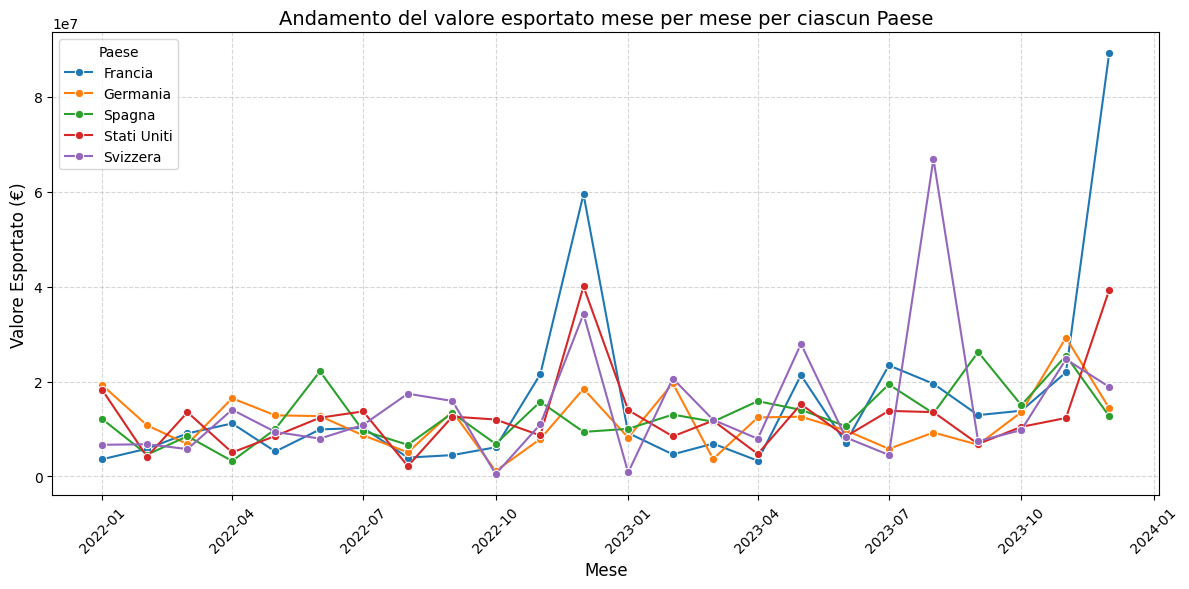

In [91]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Raggruppiamo i dati per mese e paese, calcolando la somma dei valori
andamento_paesi = ex.groupby(["mese", "paese"])["valore"].sum().reset_index()

# 2. Creiamo il grafico a linee
plt.figure(figsize=(12, 6))
sns.lineplot(data=andamento_paesi, x="mese", y="valore", hue="paese", marker="o")

# 3. Personalizziamo il grafico per renderlo leggibile
plt.title("Andamento del valore esportato mese per mese per ciascun Paese", fontsize=14)
plt.xlabel("Mese", fontsize=12)
plt.ylabel("Valore Esportato (€)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Paese")
plt.xticks(rotation=45)
plt.tight_layout()

# Mostriamo il grafico
plt.show()

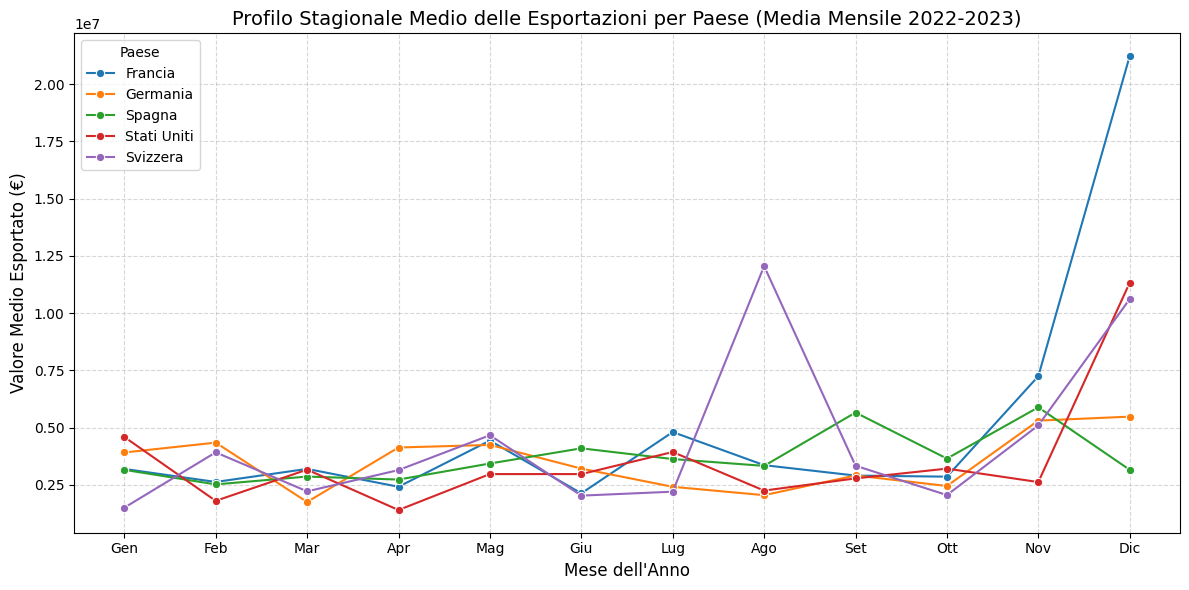

In [92]:
# 1. Estraiamo il numero del mese (1-12) e il nome del mese per l'analisi stagionale
ex["mese_num"] = ex["mese"].dt.month

# 2. Calcoliamo la media delle esportazioni totali mensili per ciascun mese dell'anno
stagionalita = ex.groupby(["mese_num", "paese"])["valore"].mean().reset_index()

# Mappiamo i numeri ai nomi dei mesi in italiano per una lettura migliore sul grafico
nomi_mesi_it = {1: "Gen", 2: "Feb", 3: "Mar", 4: "Apr", 5: "Mag", 6: "Giu",
                 7: "Lug", 8: "Ago", 9: "Set", 10: "Ott", 11: "Nov", 12: "Dic"}
stagionalita["nome_mese"] = stagionalita["mese_num"].map(nomi_mesi_it)

# 3. Disegniamo il grafico della stagionalità media per Paese
plt.figure(figsize=(12, 6))
sns.lineplot(data=stagionalita, x="nome_mese", y="valore", hue="paese", marker="o", sort=False)

plt.title("Profilo Stagionale Medio delle Esportazioni per Paese (Media Mensile 2022-2023)", fontsize=14)
plt.xlabel("Mese dell'Anno", fontsize=12)
plt.ylabel("Valore Medio Esportato (€)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(title="Paese")
plt.tight_layout()
plt.show()

*Risposta:* ...

### 9. Un controllo di plausibilità

Calcola il prezzo medio implicito di ogni prodotto (valore totale diviso quantità totale). I prezzi hanno senso per quei prodotti?

In [ ]:
# scrivi qui il tuo codice
NON HA SENSO !!!

In [93]:
# 1. Raggruppiamo per prodotto calcolando la somma di valore e quantità
prodotti_agg = ex.groupby("prodotto")[["valore", "quantita"]].sum().reset_index()

# 2. Calcoliamo il prezzo medio implicito (valore totale / quantità totale)
prodotti_agg["prezzo_medio_implicito"] = prodotti_agg["valore"] / prodotti_agg["quantita"]

# 3. Visualizziamo il risultato ordinato per prezzo medio implicito
display(prodotti_agg.sort_values(by="prezzo_medio_implicito", ascending=False))

,prodotto,valore,quantita,prezzo_medio_implicito
1,Parmigiano 1kg,1.038908e+09,53977,19247.237342
0,Olio EVO 1L,3.872911e+08,47094,8223.789018
2,Passata 700g,1.207398e+08,54230,2226.439793
3,Pasta 500g,8.429350e+07,51839,1626.063389


*Risposta:* ...

## Le tue decisioni

Scrivi la tabella delle decisioni di pulizia che hai preso (problema, decisione, verifica), come nel debrief della L3.

*Risposta:*
| Problema | Decisione | Verifica |
|---|---|---|
| ... | ... | ... |

## Consegna

1. Ultimo commit e push: **File → Salva una copia in GitHub**, messaggio `E4: completata`.
2. Sul tuo fork apri il file e copia l'indirizzo: `https://github.com/<tuo-utente>/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb`.
3. Mandalo a `andrelorenzon+sima2026@gmail.com`, con oggetto `E4 - <cognomi del gruppo>`.
4. **Gli altri due del gruppo:** aprite in Colab il notebook dal fork di chi ha scritto (`https://colab.research.google.com/github/<suo-utente>/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb`) e con **File → Salva una copia in GitHub** salvatelo nel **vostro** fork. Così ognuno ha la sua copia e ha fatto il suo push.

✅ *Controllo:* il link del punto 2 si apre anche da una finestra in incognito.